# BAN240 Capstone – Python Data Analysis

**Research question**
How did mortgage interest rate changes relate to the price gap between condominiums and townhouses in the Greater Toronto Area from 2016 to 2025?

**Sub-questions**
1. Does the gap widen when rates rise?
2. How many months until the gap reacts?
3. Is the link different in low, rising and falling rate periods?

**Data**
| File | Source | What we use |
|---|---|---|
| `Not Seasonally Adjusted (M).xlsx` | CREA MLS® Home Price Index | Sheet `GREATER_TORONTO`: `Townhouse_Benchmark`, `Apartment_Benchmark` |
| `A4_RATES_MORTGAGES-sd-2013-01-01.csv` | Bank of Canada, Table A4 | Series `V122667781`: new uninsured residential mortgages, total (funds advanced) |

**How to run**
Put both data files in the same folder as this notebook, then choose *Run All*.

## Step 1 – Import libraries
Each library has one job.

In [1]:
import pandas as pd                 # tables and data cleaning
import numpy as np                  # maths on columns
import matplotlib.pyplot as plt     # charts
from scipy import stats             # correlation and regression tests

# Show numbers with 2 decimals and wider tables
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.width", 120)

# One consistent chart style for the whole report
plt.rcParams.update({
    "figure.figsize": (10, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})
TOWN_COLOR, CONDO_COLOR, RATE_COLOR, GAP_COLOR = "#2F5D7C", "#9AA5B1", "#C0504D", "#2F5D7C"

## Step 2 – Settings
All choices that could change are kept in one place, so the group can edit them easily.

In [2]:
CREA_FILE = "Not Seasonally Adjusted (M).xlsx"          # CREA price file
BOC_FILE  = "A4_RATES_MORTGAGES-sd-2013-01-01.csv"      # Bank of Canada rate file
CREA_SHEET = "GREATER_TORONTO"                           # GTA sheet
RATE_SERIES = "V122667781"                               # uninsured new mortgages, total

START, END = "2016-01-01", "2025-12-01"                  # study period

# Mortgage assumptions for the "extra monthly payment" estimate
AMORTIZATION_YEARS = 25      # Canadian standard amortization
MAX_LAG = 12                 # test lags of 0 to 12 months

# Rate periods for sub-question 3, based on Bank of Canada policy moves
PERIODS = {
    "Stable (2016-01 to 2020-02)":  ("2016-01-01", "2020-02-01"),   # before COVID
    "Low (2020-03 to 2022-02)":     ("2020-03-01", "2022-02-01"),   # emergency low rates
    "Rising (2022-03 to 2023-12)":  ("2022-03-01", "2023-12-01"),   # fast hikes
    "Falling (2024-01 to 2025-12)": ("2024-01-01", "2025-12-01"),   # rate cuts
}

## Step 3 – Load the CREA house price data
We keep only the date and the two benchmark prices we need.

- `Townhouse_Benchmark` = typical townhouse price
- `Apartment_Benchmark` = typical condo apartment price

In [3]:
# Read one sheet from the Excel file
prices = pd.read_excel(CREA_FILE, sheet_name=CREA_SHEET)

# Keep 3 columns and give them short names
prices = prices[["Date", "Townhouse_Benchmark", "Apartment_Benchmark"]].rename(
    columns={"Date": "date", "Townhouse_Benchmark": "townhouse", "Apartment_Benchmark": "condo"}
)

# Make sure the date is a real date, set to the first day of the month
prices["date"] = pd.to_datetime(prices["date"]).dt.to_period("M").dt.to_timestamp()

print(prices.shape)        # rows, columns
prices.head()

(260, 3)


,date,townhouse,condo
0,2005-01-01,210100,198300
1,2005-02-01,211600,199700
2,2005-03-01,212800,201200
3,2005-04-01,213900,201600
4,2005-05-01,215200,204900


## Step 4 – Load the Bank of Canada rate data
The CSV starts with notes (terms, description, series list). The real table begins after the line `"OBSERVATIONS"`, so we find that line first.

In [4]:
# Find the line number where the data table starts
with open(BOC_FILE, encoding="utf-8-sig") as f:
    lines = f.readlines()
header_row = next(i for i, line in enumerate(lines) if line.strip().strip('"') == "OBSERVATIONS") + 1

# Read the table from that line, keep the date and our one series
rates = pd.read_csv(BOC_FILE, skiprows=header_row, usecols=["date", RATE_SERIES])
rates = rates.rename(columns={RATE_SERIES: "rate"})
rates["date"] = pd.to_datetime(rates["date"]).dt.to_period("M").dt.to_timestamp()

# Turn text into numbers; blanks become NaN (missing)
rates["rate"] = pd.to_numeric(rates["rate"], errors="coerce")

print(rates.shape)
rates.head()

(163, 2)


,date,rate
0,2013-01-01,3.14
1,2013-02-01,3.12
2,2013-03-01,3.07
3,2013-04-01,3.03
4,2013-05-01,3.01


## Step 5 – Merge and check data quality
We join the two tables on the month and keep only 2016–2025. Then we check that no month is missing.

In [5]:
# Inner join: keep months that exist in BOTH tables
df = prices.merge(rates, on="date", how="inner")

# Keep the study period only
df = df[(df["date"] >= START) & (df["date"] <= END)].sort_values("date").reset_index(drop=True)

# Quality checks
expected_months = len(pd.date_range(START, END, freq="MS"))     # should be 120
print("Months expected:", expected_months)
print("Months in data:", len(df))
print("Missing values:")
print(df.isna().sum())
print("Duplicate months:", df["date"].duplicated().sum())

Months expected: 120
Months in data: 120
Missing values:
date         0
townhouse    0
condo        0
rate         0
dtype: int64
Duplicate months: 0


## Step 6 – Create the analysis variables
| Variable | Meaning |
|---|---|
| `gap` | townhouse − condo price, in dollars |
| `ratio` | townhouse ÷ condo |
| `gap_payment` | extra monthly mortgage payment to finance the gap |
| `gap_yoy`, `rate_yoy` | change versus the same month last year |

**Mortgage payment formula**
Canadian fixed-rate mortgages compound semi-annually, so the monthly rate is

$$ r_m = \left(1 + \frac{r}{2}\right)^{1/6} - 1, \qquad \text{Payment} = \frac{P \cdot r_m}{1 - (1 + r_m)^{-n}} $$

where *P* is the gap, *r* the annual rate and *n* = 25 × 12 = 300 months.

In [6]:
def monthly_payment(principal, annual_rate_pct, years=AMORTIZATION_YEARS):
    # Monthly payment with Canadian semi-annual compounding
    r = annual_rate_pct / 100                       # 5.0 -> 0.05
    r_m = (1 + r / 2) ** (1 / 6) - 1                # effective monthly rate
    n = years * 12                                  # number of payments
    return principal * r_m / (1 - (1 + r_m) ** -n)

df["gap"] = df["townhouse"] - df["condo"]                         # price gap
df["ratio"] = df["townhouse"] / df["condo"]                       # price ratio
df["gap_payment"] = monthly_payment(df["gap"], df["rate"])        # extra monthly payment
df["gap_yoy"] = df["gap"].diff(12)                                # 12-month change in gap
df["rate_yoy"] = df["rate"].diff(12)                              # 12-month change in rate
df["year"] = df["date"].dt.year                                   # year label

df.head()

,date,townhouse,condo,rate,gap,ratio,gap_payment,gap_yoy,rate_yoy,year
0,2016-01-01,390400,327500,2.68,62900,1.19,287.44,NaN,NaN,2016
1,2016-02-01,400500,332900,2.77,67600,1.20,311.99,NaN,NaN,2016
2,2016-03-01,408500,335900,2.80,72600,1.22,336.17,NaN,NaN,2016
3,2016-04-01,418100,341900,2.72,76200,1.22,349.75,NaN,NaN,2016
4,2016-05-01,427800,345700,2.67,82100,1.24,374.77,NaN,NaN,2016


## Step 7 – Descriptive statistics
First we look at the numbers before testing anything: averages, ranges and the yearly picture.

In [7]:
# Summary of the main variables
summary = df[["townhouse", "condo", "gap", "ratio", "rate", "gap_payment"]].describe().T
summary[["mean", "min", "max", "std"]]

,mean,min,max,std
townhouse,"653,979.17","390,400.00","905,600.00","130,297.20"
condo,"549,457.50","327,500.00","730,500.00","98,754.66"
gap,"104,521.67","36,500.00","177,400.00","42,744.51"
ratio,1.19,1.06,1.27,0.06
rate,3.65,1.88,6.43,1.31
gap_payment,547.31,170.68,995.03,270.30


In [8]:
# Where are the lowest and highest rates?
low = df.loc[df["rate"].idxmin()]
high = df.loc[df["rate"].idxmax()]
print(f"Lowest rate:  {low['rate']:.2f}% in {low['date']:%B %Y}")
print(f"Highest rate: {high['rate']:.2f}% in {high['date']:%B %Y}")

# Annual averages: one row per year
annual = df.groupby("year").agg(
    townhouse=("townhouse", "mean"),
    condo=("condo", "mean"),
    gap=("gap", "mean"),
    ratio=("ratio", "mean"),
    rate=("rate", "mean"),
)
# Payment on the annual average gap at the annual average rate
annual["gap_payment"] = monthly_payment(annual["gap"], annual["rate"])
annual["gap_$K"] = annual["gap"] / 1000
annual[["townhouse", "condo", "gap_$K", "ratio", "rate", "gap_payment"]].round(2)

Lowest rate:  1.88% in October 2021
Highest rate: 6.43% in December 2023


,townhouse,condo,gap_$K,ratio,rate,gap_payment
year,,,,,,
2016,"435,333.33","352,550.00",82.78,1.23,2.67,377.78
2017,"527,875.00","439,583.33",88.29,1.20,2.88,412.31
2018,"535,283.33","482,375.00",52.91,1.11,3.42,261.88
2019,"561,750.00","516,066.67",45.68,1.09,3.33,224.12
2020,"625,041.67","561,208.33",63.83,1.11,2.58,288.63
2021,"742,558.33","621,783.33",120.78,1.19,1.95,508.51
2022,"826,341.67","678,616.67",147.72,1.22,3.74,756.19
2023,"786,308.33","640,975.00",145.33,1.23,5.82,914.36
2024,"770,791.67","621,191.67",149.60,1.24,5.53,916.05


## Step 8 – Trend charts
Chart 1 shows the two prices. Chart 2 puts the gap and the rate on the same timeline (two y-axes). Chart 3 shows what the gap costs a buyer each month.

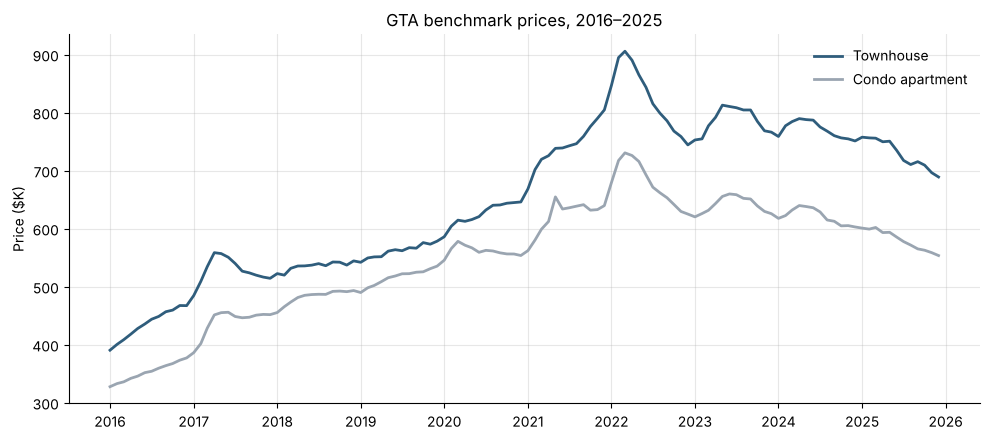

In [9]:
# Chart 1: townhouse vs condo benchmark price
fig, ax = plt.subplots()
ax.plot(df["date"], df["townhouse"] / 1000, color=TOWN_COLOR, lw=2, label="Townhouse")
ax.plot(df["date"], df["condo"] / 1000, color=CONDO_COLOR, lw=2, label="Condo apartment")
ax.set_title("GTA benchmark prices, 2016–2025")
ax.set_ylabel("Price ($K)")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("chart1_prices.png", dpi=200)     # save for the report
plt.show()

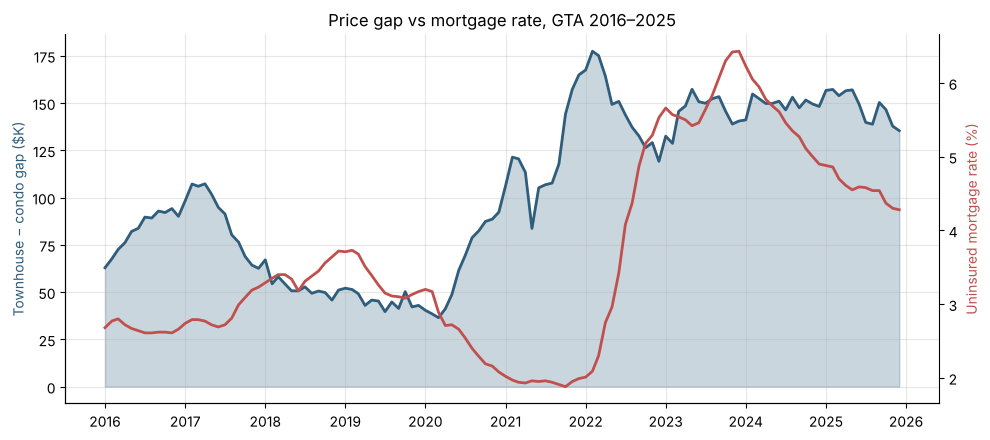

In [10]:
# Chart 2: price gap (left axis) and mortgage rate (right axis)
fig, ax1 = plt.subplots()
ax1.fill_between(df["date"], df["gap"] / 1000, color=GAP_COLOR, alpha=0.25)
ax1.plot(df["date"], df["gap"] / 1000, color=GAP_COLOR, lw=2, label="Price gap ($K)")
ax1.set_ylabel("Townhouse − condo gap ($K)", color=GAP_COLOR)

ax2 = ax1.twinx()                       # second y-axis sharing the same x-axis
ax2.plot(df["date"], df["rate"], color=RATE_COLOR, lw=2, label="Mortgage rate (%)")
ax2.set_ylabel("Uninsured mortgage rate (%)", color=RATE_COLOR)
ax2.grid(False)
ax2.spines["right"].set_visible(True)

ax1.set_title("Price gap vs mortgage rate, GTA 2016–2025")
plt.tight_layout()
plt.savefig("chart2_gap_vs_rate.png", dpi=200)
plt.show()

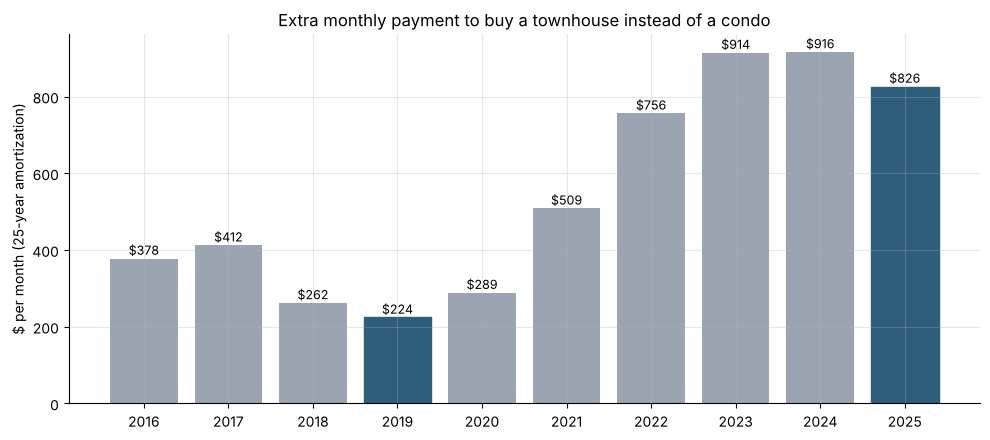

In [11]:
# Chart 3: extra monthly payment to finance the gap (annual average)
fig, ax = plt.subplots()
bars = ax.bar(annual.index.astype(str), annual["gap_payment"], color=CONDO_COLOR)
bars[list(annual.index).index(2019)].set_color(TOWN_COLOR)     # highlight 2019
bars[-1].set_color(TOWN_COLOR)                                  # highlight last year
for b, v in zip(bars, annual["gap_payment"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 10, f"${v:,.0f}", ha="center", fontsize=9)
ax.set_title("Extra monthly payment to buy a townhouse instead of a condo")
ax.set_ylabel("$ per month (25-year amortization)")
plt.tight_layout()
plt.savefig("chart3_gap_payment.png", dpi=200)
plt.show()

## Step 9 – Sub-question 1: does the gap widen when rates rise?
We use **Pearson correlation** (*r*, from −1 to +1).
- *r* > 0: gap and rate move in the same direction
- *r* < 0: they move in opposite directions
- *p*-value < 0.05: the link is unlikely to be pure chance

We test two versions.
1. **Levels** – the raw monthly values.
2. **12-month changes** – removes the long-run trend, so two series that both just grow over time do not look related by accident.

In [12]:
def corr_test(x, y):
    # Pearson correlation on rows where both values exist
    pair = pd.concat([x, y], axis=1).dropna()
    r, p = stats.pearsonr(pair.iloc[:, 0], pair.iloc[:, 1])
    return r, p, len(pair)

results_q1 = pd.DataFrame(
    [
        ("Levels: gap vs rate", *corr_test(df["gap"], df["rate"])),
        ("Levels: ratio vs rate", *corr_test(df["ratio"], df["rate"])),
        ("12-month change: gap vs rate", *corr_test(df["gap_yoy"], df["rate_yoy"])),
    ],
    columns=["test", "r", "p_value", "n_months"],
).set_index("test")
results_q1

,r,p_value,n_months
test,,,
Levels: gap vs rate,0.48,0.00,120
Levels: ratio vs rate,0.33,0.00,120
12-month change: gap vs rate,-0.33,0.00,108


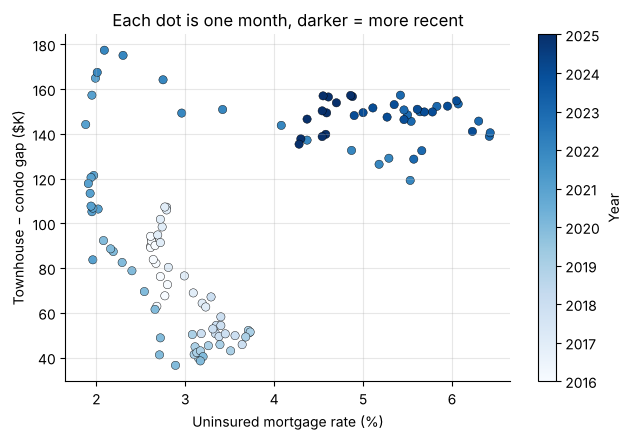

In [13]:
# Scatter plot: each dot is one month
fig, ax = plt.subplots(figsize=(6.5, 4.5))
sc = ax.scatter(df["rate"], df["gap"] / 1000, c=df["year"], cmap="Blues", edgecolor="k", lw=0.3)
ax.set_xlabel("Uninsured mortgage rate (%)")
ax.set_ylabel("Townhouse − condo gap ($K)")
ax.set_title("Each dot is one month, darker = more recent")
plt.colorbar(sc, label="Year")
plt.tight_layout()
plt.savefig("chart4_scatter.png", dpi=200)
plt.show()

## Step 10 – Sub-question 2: how many months until the gap reacts?
**Lagged correlation**: we compare the gap *this* month with the rate *k* months earlier, for k = 0 to 12. The lag with the strongest correlation suggests how long the market takes to react.


`shift(k)` moves the rate column down by k rows, so each row pairs the gap with an older rate.

In [14]:
lag_rows = []
for k in range(0, MAX_LAG + 1):
    r_lvl, p_lvl, _ = corr_test(df["gap"], df["rate"].shift(k))            # levels
    r_chg, p_chg, _ = corr_test(df["gap_yoy"], df["rate_yoy"].shift(k))    # 12-month changes
    lag_rows.append({"lag_months": k, "r_levels": r_lvl, "p_levels": p_lvl,
                     "r_changes": r_chg, "p_changes": p_chg})
lags = pd.DataFrame(lag_rows).set_index("lag_months")

best_lvl = lags["r_levels"].abs().idxmax()      # lag with the strongest link
best_chg = lags["r_changes"].abs().idxmax()
print(f"Strongest lag, levels:  {best_lvl} months, r = {lags.loc[best_lvl, 'r_levels']:.2f}")
print(f"Strongest lag, changes: {best_chg} months, r = {lags.loc[best_chg, 'r_changes']:.2f}")
lags

Strongest lag, levels:  0 months, r = 0.48
Strongest lag, changes: 3 months, r = -0.39


,r_levels,p_levels,r_changes,p_changes
lag_months,,,,
0,0.48,0.00,-0.33,0.00
1,0.45,0.00,-0.37,0.00
2,0.44,0.00,-0.39,0.00
3,0.42,0.00,-0.39,0.00
4,0.41,0.00,-0.38,0.00
5,0.40,0.00,-0.36,0.00
6,0.39,0.00,-0.33,0.00
7,0.38,0.00,-0.30,0.00
8,0.37,0.00,-0.28,0.01


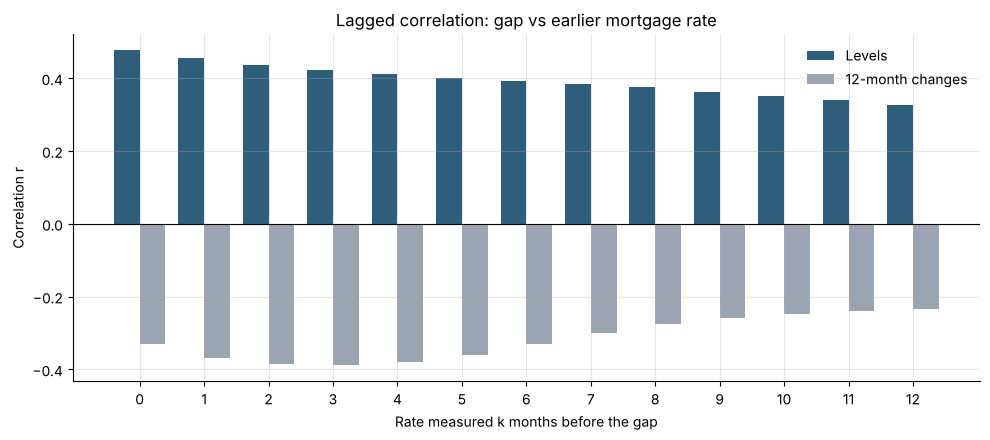

In [15]:
# Chart 5: correlation at each lag
fig, ax = plt.subplots()
x = np.arange(len(lags))
ax.bar(x - 0.2, lags["r_levels"], width=0.4, color=TOWN_COLOR, label="Levels")
ax.bar(x + 0.2, lags["r_changes"], width=0.4, color=CONDO_COLOR, label="12-month changes")
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(x, lags.index)
ax.set_xlabel("Rate measured k months before the gap")
ax.set_ylabel("Correlation r")
ax.set_title("Lagged correlation: gap vs earlier mortgage rate")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("chart5_lags.png", dpi=200)
plt.show()

## Step 11 – Sub-question 3: is the link different by rate period?
We split the 10 years into the four periods set in Step 2 and compare them.

In [16]:
period_rows = []
for name, (start, end) in PERIODS.items():
    part = df[(df["date"] >= start) & (df["date"] <= end)]            # rows in this period
    r, p, n = corr_test(part["gap"], part["rate"])
    period_rows.append({
        "period": name,
        "months": n,
        "avg_rate_%": part["rate"].mean(),                                # average rate
        "rate_change_pts": part["rate"].iloc[-1] - part["rate"].iloc[0], # rate change in the period
        "gap_start_$K": part["gap"].iloc[0] / 1000,                       # gap at start
        "gap_end_$K": part["gap"].iloc[-1] / 1000,                        # gap at end
        "gap_change_$K": (part["gap"].iloc[-1] - part["gap"].iloc[0]) / 1000,
        "r_gap_vs_rate": r,                                               # correlation inside period
        "p_value": p,
    })
periods = pd.DataFrame(period_rows).set_index("period")
periods

,months,avg_rate_%,rate_change_pts,gap_start_$K,gap_end_$K,gap_change_$K,r_gap_vs_rate,p_value
period,,,,,,,,
Stable (2016-01 to 2020-02),50,3.08,0.49,62.90,38.50,-24.40,-0.78,0.00
Low (2020-03 to 2022-02),24,2.17,-0.80,36.50,177.40,140.90,-0.78,0.00
Rising (2022-03 to 2023-12),22,5.03,4.13,175.10,140.50,-34.60,-0.48,0.02
Falling (2024-01 to 2025-12),24,5.05,-1.95,141.10,135.40,-5.70,0.22,0.30


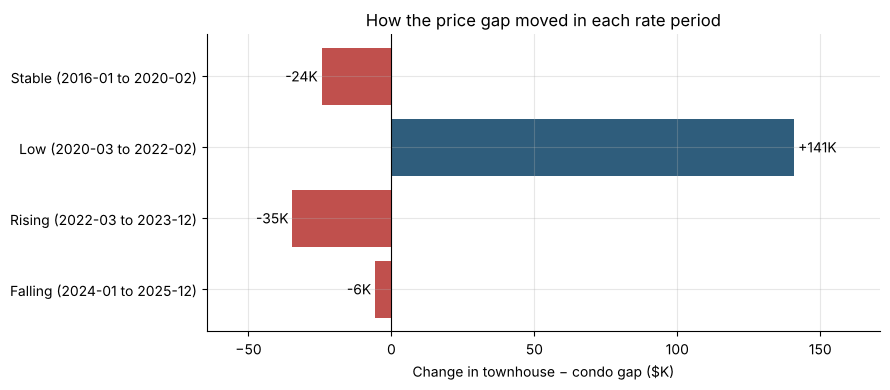

In [17]:
# Chart 6: gap change in each period
fig, ax = plt.subplots(figsize=(9, 4))
colors = [TOWN_COLOR if v >= 0 else RATE_COLOR for v in periods["gap_change_$K"]]
ax.barh(periods.index, periods["gap_change_$K"], color=colors)
for i, v in enumerate(periods["gap_change_$K"]):
    ax.text(v, i, f" {v:+.0f}K " , va="center", ha="left" if v >= 0 else "right")   # label outside the bar
ax.axvline(0, color="k", lw=0.8)
ax.set_xlim(periods["gap_change_$K"].min() - 30, periods["gap_change_$K"].max() + 30)   # room for labels
ax.invert_yaxis()
ax.set_xlabel("Change in townhouse − condo gap ($K)")
ax.set_title("How the price gap moved in each rate period")
plt.tight_layout()
plt.savefig("chart6_periods.png", dpi=200)
plt.show()

## Step 12 – Simple regression
Regression puts a number on the link: *how many dollars does the gap change when the rate is 1 percentage point higher?*

$$ \text{gap}_t = a + b \times \text{rate}_{t-k} $$

- *b* (slope): dollars of gap per 1 point of rate
- *R²*: share of the gap's movement explained by the rate (0 to 1)

In [18]:
def simple_regression(y, x, label):
    pair = pd.concat([y, x], axis=1).dropna()
    res = stats.linregress(pair.iloc[:, 1], pair.iloc[:, 0])     # x first, y second
    return {"model": label, "slope_b": res.slope, "intercept_a": res.intercept,
            "R2": res.rvalue ** 2, "p_value": res.pvalue, "n": len(pair)}

reg = pd.DataFrame([
    simple_regression(df["gap"], df["rate"], "gap ~ rate (same month)"),
    simple_regression(df["gap_yoy"], df["rate_yoy"], "12-month change: gap ~ rate"),
    simple_regression(df["gap_yoy"], df["rate_yoy"].shift(best_chg),
                      f"12-month change, rate lagged {best_chg} months"),
]).set_index("model")
reg

,slope_b,intercept_a,R2,p_value,n
model,,,,,
gap ~ rate (same month),"15,564.86","47,725.49",0.23,0.00,120
12-month change: gap ~ rate,"-8,687.97","9,111.10",0.11,0.00,108
"12-month change, rate lagged 3 months","-10,185.34","8,862.91",0.15,0.00,105


## Step 13 – Key findings
The cell below writes the main numbers as sentences, so the group can paste them into the report and slides.

In [19]:
a19, a25 = annual.loc[2019], annual.loc[2025]
q1 = results_q1.iloc[0]
q1c = results_q1.iloc[2]

print("KEY FINDINGS")
print("-" * 60)
print(f"1. The average gap grew from ${a19['gap']/1000:,.1f}K in 2019 to ${a25['gap']/1000:,.1f}K in 2025 "
      f"({a25['gap']/a19['gap']:.1f}x).")
print(f"2. The extra monthly payment on the gap rose from ${a19['gap_payment']:,.0f} (2019) to ${a25['gap_payment']:,.0f} (2025).")
print(f"3. Levels: r = {q1['r']:.2f} (p = {q1['p_value']:.3f}). 12-month changes: r = {q1c['r']:.2f} (p = {q1c['p_value']:.3f}).")
direction = "narrows" if q1c["r"] < 0 else "widens"
print(f"   Short-run reading: when the rate rises faster than a year ago, the gap usually {direction}.")
print(f"4. Strongest lag: {best_lvl} months (levels), {best_chg} months (12-month changes).")
print("5. By rate period:")
for name, row in periods.iterrows():
    print(f"   {name}: rate {row['rate_change_pts']:+.2f} pts, gap {row['gap_change_$K']:+.1f}K")

KEY FINDINGS
------------------------------------------------------------
1. The average gap grew from $45.7K in 2019 to $148.3K in 2025 (3.2x).
2. The extra monthly payment on the gap rose from $224 (2019) to $826 (2025).
3. Levels: r = 0.48 (p = 0.000). 12-month changes: r = -0.33 (p = 0.000).
   Short-run reading: when the rate rises faster than a year ago, the gap usually narrows.
4. Strongest lag: 0 months (levels), 3 months (12-month changes).
5. By rate period:
   Stable (2016-01 to 2020-02): rate +0.49 pts, gap -24.4K
   Low (2020-03 to 2022-02): rate -0.80 pts, gap +140.9K
   Rising (2022-03 to 2023-12): rate +4.13 pts, gap -34.6K
   Falling (2024-01 to 2025-12): rate -1.95 pts, gap -5.7K


### How to read these results
- **Correlation is not causation.** The rate is one factor. The 2017 Ontario foreign buyer tax, the 2018 mortgage stress test, and COVID-19 (demand for more space) also moved prices.
- **The rate is national, the prices are GTA.** Table A4 is a Canada-wide average, so it does not capture local lending differences.

- **Levels vs changes.** If the link is strong in levels but weak in 12-month changes, much of it may come from both series trending over time, not from month-to-month reactions.
- **Payment figures are estimates.** They assume the whole gap is borrowed at the average new uninsured rate over 25 years.

## Step 14 – Save the results
These files can be shared with the group or used in Power BI / Excel.

In [20]:
df.to_csv("analysis_dataset_monthly.csv", index=False)          # monthly merged data
annual.to_csv("analysis_annual_summary.csv")                     # yearly table
lags.to_csv("analysis_lag_correlations.csv")                     # lag results
periods.to_csv("analysis_period_comparison.csv")                 # period results
print("Saved 4 CSV files and 6 PNG charts.")

Saved 4 CSV files and 6 PNG charts.
